<a href="https://colab.research.google.com/github/mihaipopa15/unit-testing-junit/blob/main/lab3biaex1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, random_state=42)

# Set test_size to 0.45 for a 45% test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.45, random_state=0)

In [36]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier(n_neighbors=2)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=2)

In [37]:
clf.predict(X_test)

array([0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 0])

In [38]:
clf.score(X_test, y_test)

1.0

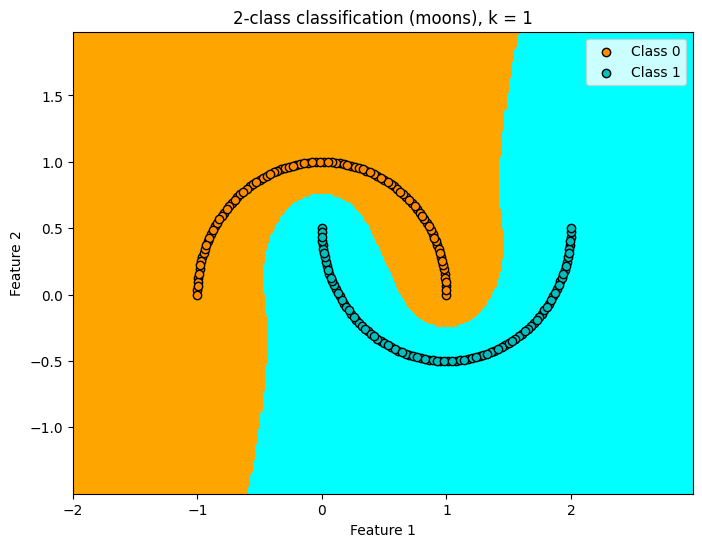

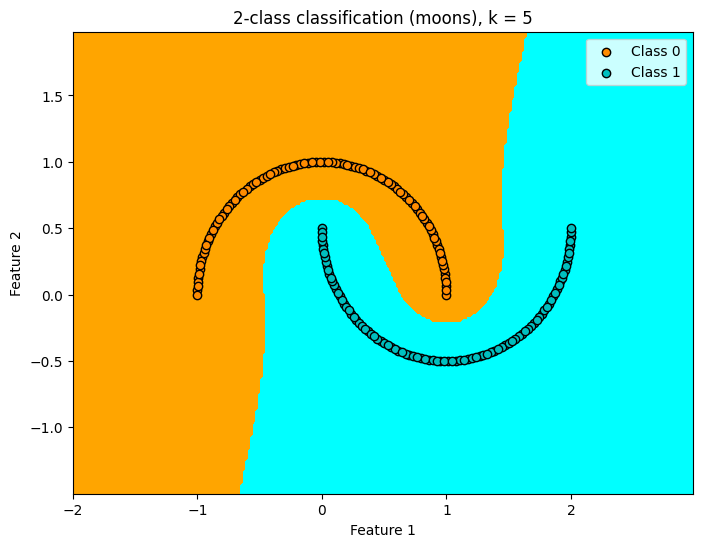

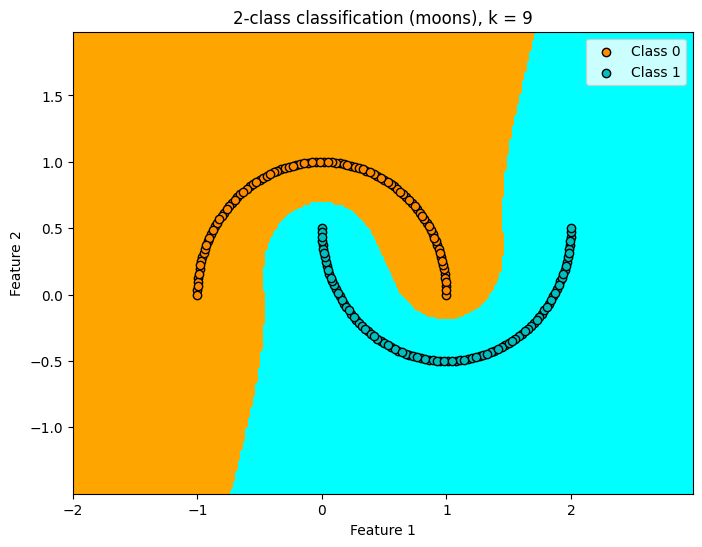

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

# Unpack the moons dataset directly into X and y
X, y = make_moons(n_samples=200, random_state=42)

h = 0.02  # Step size in the mesh

# Create color maps for 2 classes
cmap_light = ListedColormap(["orange", "cyan"])
cmap_bold = ["darkorange", "c"]

for n_neighbors in [1, 5, 9]:
    # We create an instance of KNeighborsClassifier and fit the data.
    clf = KNeighborsClassifier(n_neighbors)
    clf.fit(X, y)

    # Plot the decision boundary.
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, cmap=cmap_light)

    # Plot also the training points for 2 classes
    for i in range(2):
      plt.scatter(X[:, 0][y==i], X[:, 1][y==i], c=cmap_bold[i],
                  edgecolors="black", label=f"Class {i}")

    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title("2-class classification (moons), k = %i" % (n_neighbors))
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()

plt.show()